# 05 — Waveform preprocessing V2

This pipeline corrects the annotated-channel mismatch in the baseline and
preserves the complete 10-second waveform for temporal modeling.

- `PPG_R` is used because BUT PPG quality labels were created from red PPG.
- Each record becomes three aligned views: robust raw, Butterworth band-pass,
  and first derivative.
- The original subject-disjoint split is retained.
- No label-dependent transformation or overlapping cross-subject windowing is used.

In [1]:
from pathlib import Path
import os
import sys


def find_repository_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "apps").exists():
            return candidate
    raise RuntimeError("Run this notebook from inside the pure-pulsesure repository")


REPO_ROOT = find_repository_root(Path.cwd().resolve())
AI_SERVICE_ROOT = REPO_ROOT / "apps" / "ai-service"
sys.path.insert(0, str(AI_SERVICE_ROOT))

RAW_DIR = Path(
    os.environ.get("PURE_BUT_PPG_DIR", REPO_ROOT / "data" / "raw" / "but-ppg-2.0.0")
).expanduser().resolve()
WAVEFORM_DIR = Path(
    os.environ.get("PURE_WAVEFORM_DIR", REPO_ROOT / "data" / "processed" / "but-ppg-waveforms-v2")
).expanduser().resolve()
MODEL_DIR = Path(os.environ.get("PURE_MODEL_DIR", REPO_ROOT / "models")).expanduser().resolve()

print("Repository:", REPO_ROOT)
print("Raw dataset:", RAW_DIR)
print("Waveform dataset:", WAVEFORM_DIR)
print("Model directory:", MODEL_DIR)

Repository: /mnt/home/gracewahyuni06/pure-pulsesure
Raw dataset: /mnt/home/gracewahyuni06/pure-pulsesure/data/raw/but-ppg-2.0.0
Waveform dataset: /mnt/home/gracewahyuni06/pure-pulsesure/data/processed/but-ppg-waveforms-v2
Model directory: /mnt/home/gracewahyuni06/pure-pulsesure/models


In [2]:
import subprocess

command = [
    sys.executable,
    str(REPO_ROOT / "scripts" / "prepare_but_ppg_waveforms.py"),
    "--raw-dir", str(RAW_DIR),
    "--output-dir", str(WAVEFORM_DIR),
]
subprocess.run(command, check=True)

{
  "created_at_utc": "2026-10-20T06:14:16.360665+00:00",
  "dataset": "BUT PPG v2.0.0",
  "source_url": "https://physionet.org/content/butppg/2.0.0/",
  "array_shape": [
    3888,
    3,
    300
  ],
  "view_order": [
    "raw_robust",
    "butterworth_bandpass",
    "first_derivative"
  ],
  "annotated_channel_policy": "PPG_R, then PPG_G/PPG_B only as fallback",
  "preprocessing": {
    "sampling_rate_hz": 30.0,
    "low_cut_hz": 0.5,
    "high_cut_hz": 5.0,
    "filter_order": 4,
    "robust_clip": 10.0,
    "epsilon": 1e-08
  },
  "seed": 2026,
  "split_subjects": {
    "train": [
      "100",
      "101",
      "102",
      "103",
      "105",
      "106",
      "108",
      "109",
      "110",
      "111",
      "112",
      "113",
      "116",
      "117",
      "118",
      "119",
      "120",
      "121",
      "122",
      "124",
      "125",
      "127",
      "129",
      "130",
      "132",
      "133",
      "135",
      "136",
      "138",
      "143",
      "144",
     

CompletedProcess(args=['/mnt/home/gracewahyuni06/pure-pulsesure/.venv/bin/python', '/mnt/home/gracewahyuni06/pure-pulsesure/scripts/prepare_but_ppg_waveforms.py', '--raw-dir', '/mnt/home/gracewahyuni06/pure-pulsesure/data/raw/but-ppg-2.0.0', '--output-dir', '/mnt/home/gracewahyuni06/pure-pulsesure/data/processed/but-ppg-waveforms-v2'], returncode=0)

In [3]:
import json
import numpy as np
import pandas as pd

archive = np.load(WAVEFORM_DIR / "waveforms.npz")
X, y = archive["X"], archive["y"]
metadata = pd.DataFrame({
    "record_id": archive["record_id"],
    "subject_id": archive["subject_id"],
    "split": archive["split"],
    "label_good_quality": y,
    "selected_channel": archive["selected_channel"],
})
print("X shape:", X.shape)
print("finite:", bool(np.isfinite(X).all()))
display(pd.crosstab(metadata["split"], metadata["label_good_quality"], margins=True))
display(pd.crosstab(metadata["selected_channel"], metadata["label_good_quality"], margins=True))
json.loads((WAVEFORM_DIR / "manifest.json").read_text())

X shape: (3888, 3, 300)
finite: True


label_good_quality,0,1,All
split,,,
test,470,170,640
train,1969,519,2488
validation,619,141,760
All,3058,830,3888


label_good_quality,0,1,All
selected_channel,,,
PPG_R,3045,795,3840
legacy_combined_ppg,13,35,48
All,3058,830,3888


{'created_at_utc': '2026-10-20T06:14:16.360665+00:00',
 'dataset': 'BUT PPG v2.0.0',
 'source_url': 'https://physionet.org/content/butppg/2.0.0/',
 'array_shape': [3888, 3, 300],
 'view_order': ['raw_robust', 'butterworth_bandpass', 'first_derivative'],
 'annotated_channel_policy': 'PPG_R, then PPG_G/PPG_B only as fallback',
 'preprocessing': {'sampling_rate_hz': 30.0,
  'low_cut_hz': 0.5,
  'high_cut_hz': 5.0,
  'filter_order': 4,
  'robust_clip': 10.0,
  'epsilon': 1e-08},
 'seed': 2026,
 'split_subjects': {'train': ['100',
   '101',
   '102',
   '103',
   '105',
   '106',
   '108',
   '109',
   '110',
   '111',
   '112',
   '113',
   '116',
   '117',
   '118',
   '119',
   '120',
   '121',
   '122',
   '124',
   '125',
   '127',
   '129',
   '130',
   '132',
   '133',
   '135',
   '136',
   '138',
   '143',
   '144',
   '145',
   '146',
   '147',
   '148'],
  'validation': ['107', '114', '115', '123', '128', '134', '140', '141'],
  'test': ['104', '126', '131', '137', '139', '142', 

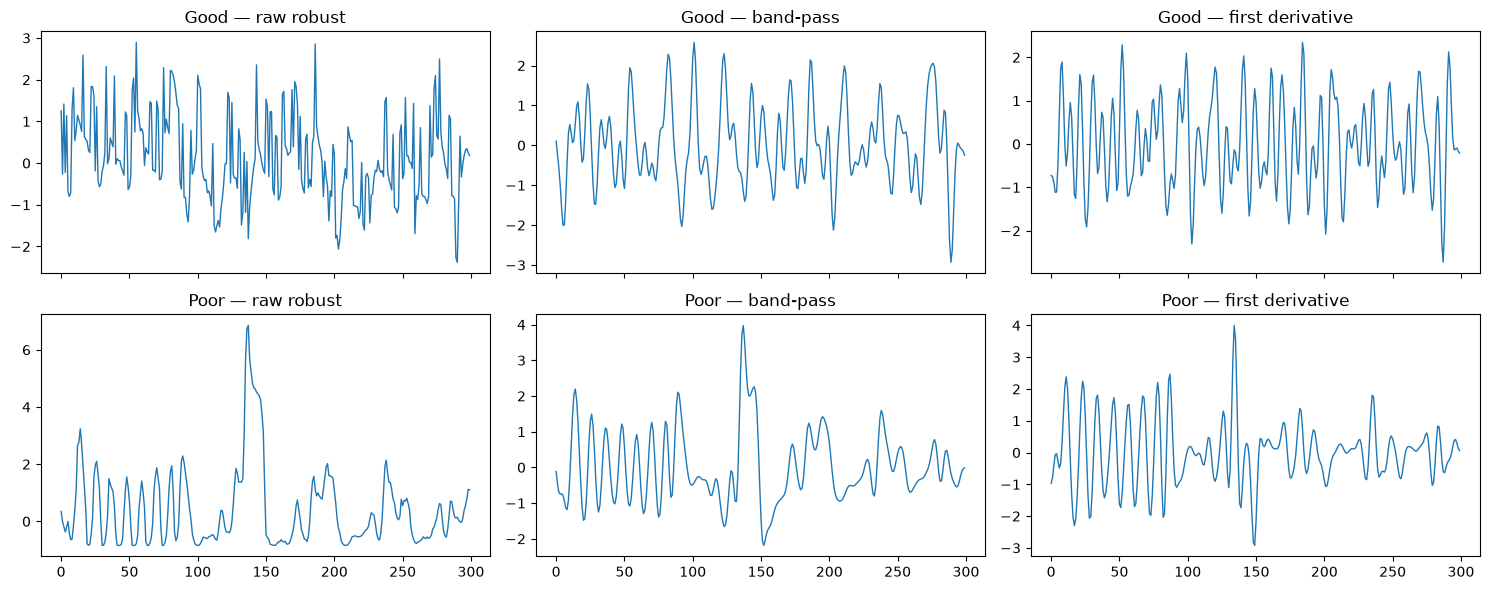

In [4]:
import matplotlib.pyplot as plt

view_names = ["raw robust", "band-pass", "first derivative"]
figure, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for row, label in enumerate([1, 0]):
    index = int(np.flatnonzero(y == label)[0])
    for column in range(3):
        axes[row, column].plot(X[index, column], linewidth=1)
        axes[row, column].set_title(f"{'Good' if label else 'Poor'} — {view_names[column]}")
plt.tight_layout()